# RODA · Ventas observadas, versiones y evaluación temporal
**Objetivo:** estimar unidades del próximo mes, comparar cinco algoritmos y demostrar el ciclo V1 → datos nuevos → V2 → evaluación posterior.

Este cuaderno usa **Car Parts, Monash Forecasting Repository**, una fuente pública de ventas mensuales de repuestos. No son ventas de RODA ni datos peruanos actuales. Sus identificadores son anónimos. No se inventan precios, existencias o fechas.

Fuente: [Zenodo, DOI 10.5281/zenodo.4656022](https://zenodo.org/records/4656022). Licencia **CC BY 4.0**. Autores: Rakshitha Godahewa, Christoph Bergmeir, Geoff Webb, Rob Hyndman y Pablo Montero-Manso. Fuente original: `expsmooth::carparts`, Hyndman (2015).

La web utiliza exactamente `ml/lab_engine.py`. El laboratorio mensual es independiente del pronóstico operativo de siete días. Un resultado técnicamente correcto no garantiza utilidad para reposición.

In [1]:
from pathlib import Path
import subprocess, sys, os
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    ROOT = Path('/content/REPUESTOS')
    if not ROOT.exists():
        subprocess.run(['git','clone','https://github.com/NEYEN111/REPUESTOS.git',str(ROOT)],check=True)
    elif not (ROOT/'ml/lab_engine.py').exists():
        subprocess.run(['git','-C',str(ROOT),'pull','--ff-only'],check=True)
    subprocess.run([sys.executable,'-m','pip','install','-q','-r',str(ROOT/'ml/requirements.txt')],check=True)
else:
    ROOT = next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'ml/lab_engine.py').is_file())
os.chdir(ROOT)
sys.path.insert(0,str(ROOT))
print('Proyecto:', ROOT)
print('Código:', subprocess.check_output(['git','rev-parse','HEAD'],text=True).strip())

Proyecto: C:\Users\neyen\OneDrive\Documentos\ChatGPT\REPUESTOS
Código: e8811446103ff317e11b18aae40a0df2b938568c


## 1. Reproducibilidad y contrato de datos
Una fila corresponde a una serie y un mes. `unidades=0` significa cero observado; vacío significa desconocido. Los meses ausentes se conservan como desconocidos. Las variables faltantes se imputan dentro del pipeline de entrenamiento; **nunca se imputa la variable objetivo**.

Las versiones de librerías se fijan. Los modelos se guardan con SHA-256 y metadatos; solo se cargan archivos generados por este proceso. Un `.joblib` de origen desconocido puede ejecutar código.

In [2]:
import csv, json, hashlib, platform, importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits
from ml.lab_engine import train, predict, compare, frame, load_model, FEATURES, metrics
from scripts.prepare_real_ml import prepare
provenance = prepare()
OUT = ROOT/'ml/runs/carparts'
OUT.mkdir(parents=True,exist_ok=True)
REPORTS = ROOT/'ml/evaluations/carparts'
REPORTS.mkdir(parents=True,exist_ok=True)
environment = {p:metadata.version(p) for p in ['numpy','pandas','scikit-learn','scipy','joblib']}
display(pd.Series(environment,name='Versión instalada'))
print('Fuente:', provenance['source_url'], '| Licencia:', provenance['license'])
print('Filas:', provenance['rows'], '| series:', provenance['series'], '| desconocidos:', provenance['missing'])
assert provenance['rows']==136374 and provenance['missing']==6122

def read_stage(name):
    rows=[]
    with (ROOT/'ml/examples/carparts'/name).open(encoding='utf-8-sig') as f:
        for r in csv.DictReader(f):
            rows.append(dict(period=r['periodo'],sku=r['sku'],units=int(r['unidades']) if r['unidades'] else None))
    return rows
initial=read_stage('01_historial_inicial.csv')
new_data=read_stage('02_datos_nuevos.csv')
later=read_stage('03_ventas_posteriores.csv')
all_records=initial+new_data+later
raw=pd.DataFrame(all_records)
assert not raw.duplicated(['sku','period']).any()
assert raw.units.dropna().ge(0).all()
display(pd.DataFrame(provenance['files'])[['name','rows']])

numpy            2.2.6
pandas           2.2.3
scikit-learn     1.7.2
scipy           1.15.3
joblib           1.5.1
Name: Versión instalada, dtype: object

Fuente: https://zenodo.org/records/4656022 | Licencia: CC BY 4.0
Filas: 136374 | series: 2674 | desconocidos: 6122


,name,rows
0,01_historial_inicial.csv,96264
1,02_datos_nuevos.csv,24066
2,03_ventas_posteriores.csv,16044


## 2. Análisis exploratorio del historial inicial
El análisis exploratorio usa solo los primeros 36 meses. Los ceros y la baja frecuencia de compra dificultan el pronóstico por producto. La cantidad de filas por sí sola no demuestra calidad ni equivale a observaciones independientes.

,Unidades observadas
count,92617.000000
mean,0.541294
std,1.330162
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,52.000000


Porcentaje de ceros entre observaciones conocidas: 73.76


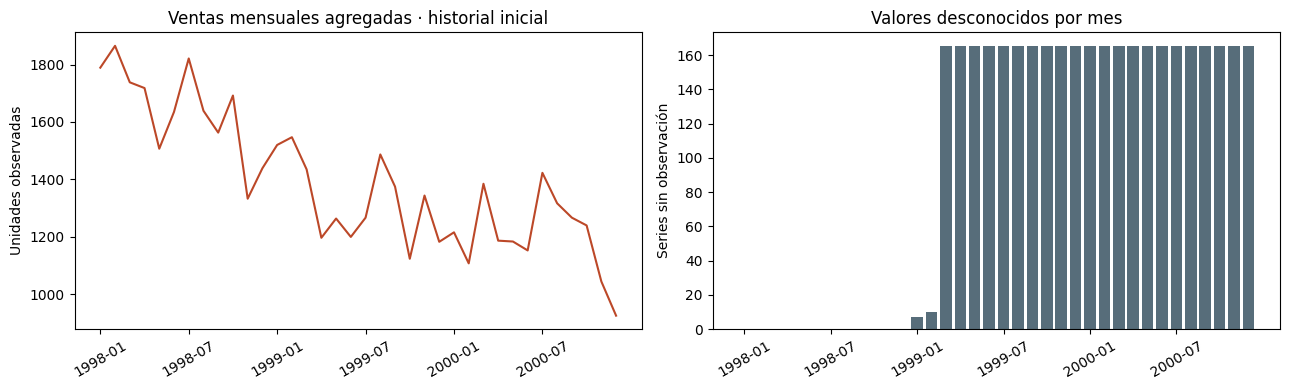

In [3]:
eda=pd.DataFrame(initial)
summary=eda.groupby('period').agg(units=('units','sum'),known=('units','count'),series=('sku','size'))
display(eda.units.describe().to_frame('Unidades observadas'))
print('Porcentaje de ceros entre observaciones conocidas:', round(100*eda.units.dropna().eq(0).mean(),2))
fig,axes=plt.subplots(1,2,figsize=(13,4))
axes[0].plot(summary.index,summary.units,color='#bc4828')
axes[0].set(title='Ventas mensuales agregadas · historial inicial',ylabel='Unidades observadas')
axes[0].set_xticks(range(0,len(summary),6),summary.index[::6],rotation=30)
axes[1].bar(summary.index,summary.series-summary.known,color='#576d7a')
axes[1].set(title='Valores desconocidos por mes',ylabel='Series sin observación')
axes[1].set_xticks(range(0,len(summary),6),summary.index[::6],rotation=30)
fig.tight_layout(); fig.savefig(REPORTS/'01_historial.png',dpi=150); plt.show()

## 3. Diseño temporal y cinco modelos

| Paso | Datos disponibles | Acción |
|---|---|---|
| V1 | Enero 1998 – diciembre 2000 | Selección en los últimos seis meses disponibles y reajuste |
| V2 | Enero 1998 – septiembre 2001 | Incorporar nueve meses, volver a seleccionar y reajustar |
| Comparación | Octubre 2001 – marzo 2002 | Evaluar V1 y V2 congeladas sobre las mismas observaciones posteriores |

Se comparan **Ridge** (referencia lineal regularizada), **Poisson** (cantidades no negativas), **Random Forest** (relaciones no lineales), **Extra Trees** (árboles aleatorizados) e **Hist. Gradient Boosting** (corrección progresiva de errores).

Configuraciones fijas, semilla 42; no se ajustan hiperparámetros mirando el periodo de comparación. La selección usa **MAE**: error medio en unidades. También se presentan RMSE, WAPE, sesgo y R². No corresponde una matriz de confusión: esta tarea es regresión, no clasificación.

La referencia simple es el promedio de los últimos 12 meses observados. Debe revisarse si los modelos lo superan. La validación es temporal con avance mensual; no se mezclan fechas aleatoriamente.

In [4]:
def run_train(records,label):
    path=OUT/(label+'.joblib')
    with threadpool_limits(limits=2):
        result=train(dict(records=records,frequency='monthly',bundle=str(path)))
    result.update(version=label,environment=environment,source=provenance['doi'],
                  data_sha256=hashlib.sha256(json.dumps(sorted(records,key=lambda r:(r['sku'],r['period'])),sort_keys=True).encode()).hexdigest())
    (REPORTS/(label+'.json')).write_text(json.dumps(result,ensure_ascii=False,indent=2),encoding='utf-8')
    print(label, '→',result['winner'],'| corte',result['cutoff'],'| supera promedio:',result['beats_baseline'])
    return result,dict(id=label,bundle=str(path),sha256=result['model_sha256'])
v1,spec1=run_train(initial,'V1')
display(pd.DataFrame(v1['candidates']).set_index('model').round(4))
print('MAE del promedio histórico:',v1['validation_baseline']['mae'])

V1 → Hist. Gradient Boosting | corte 2000-12 | supera promedio: False


,n,mae,rmse,wape,bias,r2
model,,,,,,
Ridge,15054,0.6612,1.1427,137.9037,0.0173,0.0554
Poisson,15054,0.6696,1.1675,139.6532,0.0071,0.0140
Random Forest,15054,0.6560,1.1537,136.8086,0.0010,0.0371
Extra Trees,15054,0.6554,1.1455,136.6869,0.0024,0.0508
Hist. Gradient Boosting,15054,0.6538,1.1464,136.3599,-0.0067,0.0493


MAE del promedio histórico: 0.6446071918869847


## 4. Predecir con datos nuevos no equivale a reentrenar
Primero usamos V1 para estimar enero de 2001 con lo conocido a diciembre de 2000. Después incorporamos nueve meses y entrenamos V2. Cada entrenamiento crea un archivo distinto; nunca se sobrescribe V1.

In [5]:
with threadpool_limits(limits=2):
    forecast_v1=predict(dict(records=initial,**spec1))
display(pd.DataFrame(forecast_v1['items']).head(10).round(3))
v2,spec2=run_train(initial+new_data,'V2')
display(pd.DataFrame(v2['candidates']).set_index('model').round(4))
print('MAE del promedio histórico:',v2['validation_baseline']['mae'])

,sku,period,prediction,baseline,missing
0,T100,2001-01,0.200,0.000,0
1,T1000,2001-01,0.302,0.333,0
2,T1001,2001-01,0.371,0.333,0
3,T1002,2001-01,0.200,0.000,0
4,T1003,2001-01,0.349,0.250,0
5,T1004,2001-01,0.250,0.083,0
6,T1005,2001-01,0.200,0.167,0
7,T1006,2001-01,0.228,0.250,0
8,T1007,2001-01,0.785,0.833,0
9,T1008,2001-01,0.362,0.250,0


V2 → Extra Trees | corte 2001-09 | supera promedio: False


,n,mae,rmse,wape,bias,r2
model,,,,,,
Ridge,15054,0.6394,1.1259,142.9193,0.0362,0.0658
Poisson,15054,0.6471,1.1401,144.6355,0.0260,0.0422
Random Forest,15054,0.6350,1.1289,141.9315,0.0331,0.0609
Extra Trees,15054,0.6317,1.1251,141.1926,0.0270,0.0673
Hist. Gradient Boosting,15054,0.6327,1.1279,141.4279,0.0232,0.0626


MAE del promedio histórico: 0.6071420663389576


## 5. Matriz de métricas de validación
Estas métricas sirven para seleccionar un modelo **dentro de cada versión**. V1 y V2 tienen periodos de validación diferentes, por eso no se concluye que V2 mejoró comparando solo estas tablas.

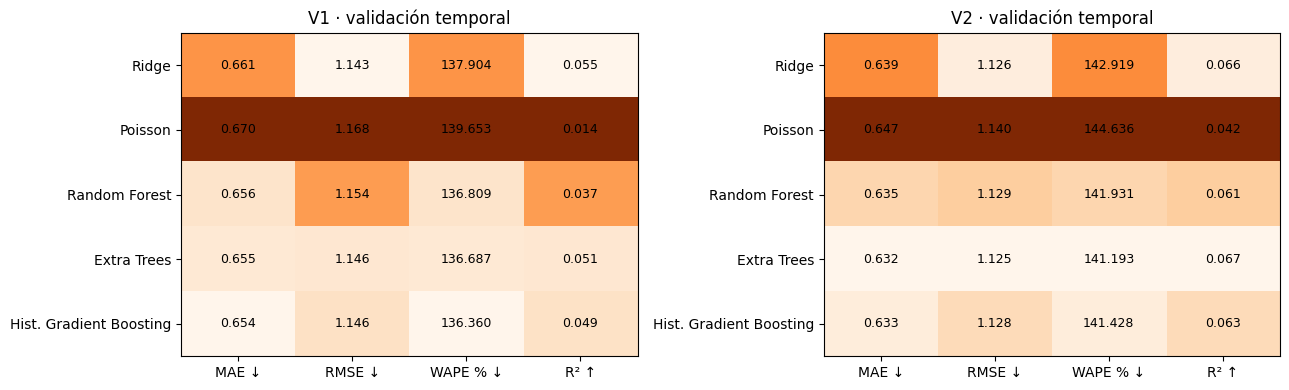

In [6]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,report,title in zip(axes,[v1,v2],['V1','V2']):
    table=pd.DataFrame(report['candidates']).set_index('model')[['mae','rmse','wape','r2']]
    normalized=(table-table.min())/(table.max()-table.min()).replace(0,1)
    normalized['r2']=1-normalized['r2']
    ax.imshow(normalized.values,cmap='Oranges',vmin=0,vmax=1,aspect='auto')
    ax.set_xticks(range(4),['MAE ↓','RMSE ↓','WAPE % ↓','R² ↑'])
    ax.set_yticks(range(5),table.index); ax.set_title(title+' · validación temporal')
    for i in range(5):
        for j in range(4): ax.text(j,i,f'{table.iloc[i,j]:.3f}',ha='center',va='center',fontsize=9)
fig.tight_layout();fig.savefig(REPORTS/'02_matriz_validacion.png',dpi=150);plt.show()

## 6. Evaluación de ambas versiones con ventas posteriores
Se utiliza exactamente el mismo conjunto de series y objetivos conocidos para ambas versiones. Cada mes puede usar las ventas observadas de meses anteriores, pero el modelo permanece congelado. **No es un pronóstico fijo de seis meses.**

Los objetivos desconocidos se excluyen; reportamos cuántos quedan. La regla de promoción, definida antes de evaluar, exige al menos 1% menos MAE. Es un umbral práctico, no una prueba de significancia estadística. Si V2 no lo cumple, se conserva V1. El periodo de comparación se utiliza para esta decisión; una versión promovida necesitará supervisión posterior sobre datos nuevos.

In [7]:
with threadpool_limits(limits=2):
    comparison=compare(dict(records=all_records,versions=[spec1,spec2]))
(REPORTS/'comparison.json').write_text(json.dumps(comparison,ensure_ascii=False,indent=2),encoding='utf-8')
score_table=pd.DataFrame(comparison['scores']+[dict(version='Promedio histórico',**comparison['baseline'])]).set_index('version')
display(score_table.round(4))
improvement=(comparison['scores'][0]['mae']-comparison['scores'][1]['mae'])/comparison['scores'][0]['mae']*100
print(f'Cambio relativo del MAE V1 → V2: {improvement:.3f}% de reducción')
print('Versión recomendada por la regla:',comparison['recommended'])
print('Filas comunes:',comparison['rows'],'| series:',comparison['products'])
print('Mejor modelo supera al promedio:',min(s['mae'] for s in comparison['scores'])<comparison['baseline']['mae'])
score_table.to_csv(REPORTS/'metricas_comparacion.csv',encoding='utf-8-sig')

,n,mae,rmse,wape,bias,r2
version,,,,,,
V1,15054,0.5747,1.0340,148.6333,0.0474,0.1023
V2,15054,0.5710,1.0331,147.6733,0.0465,0.1038
Promedio histórico,15054,0.5411,1.0460,139.9301,0.0521,0.0812


Cambio relativo del MAE V1 → V2: 0.646% de reducción
Versión recomendada por la regla: V1
Filas comunes: 15054 | series: 2509
Mejor modelo supera al promedio: False


## 7. Errores por periodo y producto
Las ventas agregadas pueden ocultar errores individuales. Se muestran ambas perspectivas. El WAPE puede superar 100% cuando el volumen real es pequeño; no debe convertirse en una supuesta «precisión porcentual».

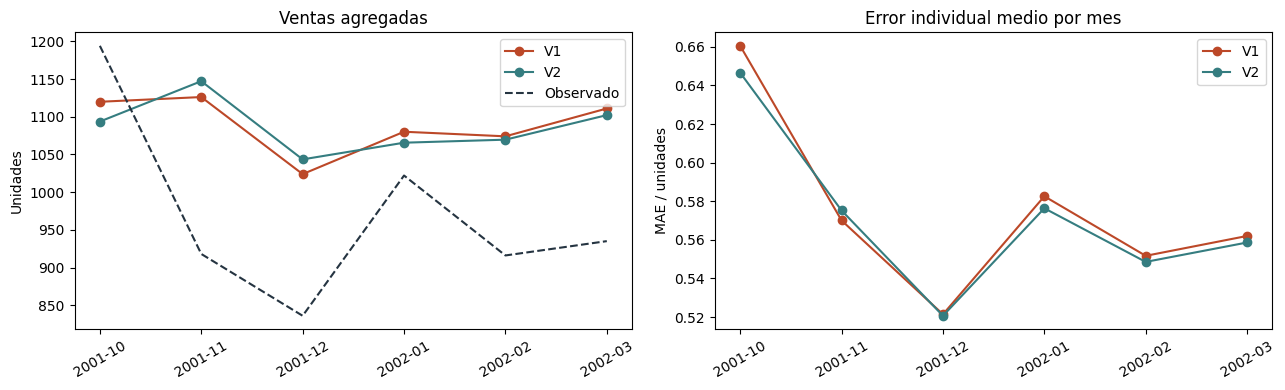

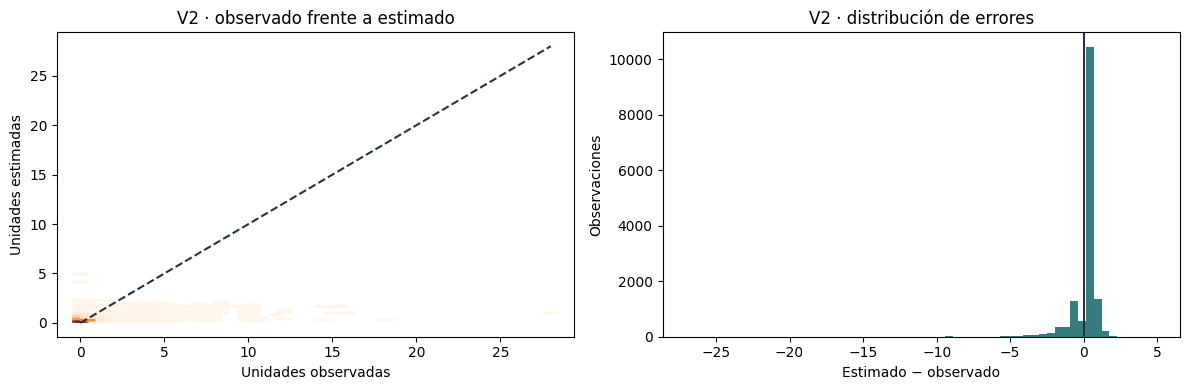

,mae,observed,predicted
sku,,,
T2475,6.243,41.0,8.481
T2348,5.100,30.0,7.893
T2587,4.315,18.0,8.513
T1863,4.201,22.0,5.831
T2369,4.074,25.0,7.946
T2614,3.822,20.0,8.405
T2438,3.730,20.0,5.819
T2257,3.615,25.0,7.195
T2618,3.530,20.0,5.972


In [8]:
periods=pd.DataFrame(comparison['periods'])
fig,axes=plt.subplots(1,2,figsize=(13,4))
for version,color in [('V1','#bc4828'),('V2','#357d80')]:
    part=periods[periods.version==version]
    axes[0].plot(part.period,part.predicted,label=version,color=color,marker='o')
    axes[1].plot(part.period,part.mae,label=version,color=color,marker='o')
part=periods[periods.version=='V1']
axes[0].plot(part.period,part.actual,label='Observado',color='#253441',linestyle='--')
axes[0].set(title='Ventas agregadas',ylabel='Unidades')
axes[1].set(title='Error individual medio por mes',ylabel='MAE / unidades')
for ax in axes: ax.legend(); ax.tick_params(axis='x',rotation=30)
fig.tight_layout();fig.savefig(REPORTS/'03_evolucion_versiones.png',dpi=150);plt.show()

features=frame(all_records,'monthly')
models=[load_model(s) for s in [spec1,spec2]]
known=set(models[0]['skus'])&set(models[1]['skus'])
test=features[features.cutoff.ge(v2['cutoff'])&features.period.gt(v2['cutoff'])&features.target.notna()&features.sku.isin(known)].copy()
assert len(test)==comparison['rows']
with threadpool_limits(limits=2):
    for label,model in zip(['V1','V2'],models):
        test[label]=np.maximum(0,model['model'].predict(test[FEATURES]))
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].hexbin(test.target,test.V2,gridsize=30,mincnt=1,cmap='Oranges')
limit=max(test.target.max(),test.V2.max());axes[0].plot([0,limit],[0,limit],'--',color='#253441')
axes[0].set(title='V2 · observado frente a estimado',xlabel='Unidades observadas',ylabel='Unidades estimadas')
axes[1].hist(test.V2-test.target,bins=60,color='#357d80')
axes[1].axvline(0,color='#253441');axes[1].set(title='V2 · distribución de errores',xlabel='Estimado − observado',ylabel='Observaciones')
fig.tight_layout();fig.savefig(REPORTS/'04_errores.png',dpi=150);plt.show()
per_sku=test.assign(error=(test.V2-test.target).abs()).groupby('sku').agg(mae=('error','mean'),observed=('target','sum'),predicted=('V2','sum'))
display(per_sku.sort_values('mae',ascending=False).head(10).round(3))
per_sku.to_csv(REPORTS/'errores_por_serie.csv',encoding='utf-8-sig')

## 8. Comprobar ausencia de fuga y generar el próximo mes
Modificar ventas posteriores no puede cambiar las variables que existían antes. La predicción siguiente se calcula con las ventas disponibles a marzo de 2002; se conserva la fecha real de la fuente. No es una predicción actual de RODA.

In [9]:
check=[dict(sku='CONTROL',period=str(p),units=i%4) for i,p in enumerate(pd.period_range('2018-01',periods=40,freq='M'))]
before=frame(check,'monthly')
check[-1]['units']=9999
after=frame(check,'monthly')
assert before[before.cutoff.lt('2021-04')][FEATURES].equals(after[after.cutoff.lt('2021-04')][FEATURES])
print('Verificación temporal: correcta.')
active=spec1 if comparison['recommended']=='V1' else spec2
with threadpool_limits(limits=2):
    forecast=predict(dict(records=all_records,**active))
predictions=pd.DataFrame(forecast['items'])
predictions['version']=active['id'];predictions['cutoff']=forecast['cutoff']
predictions.to_csv(OUT/'predicciones.csv',index=False,encoding='utf-8-sig')
display(predictions.head(12).round(3))
print('Series excluidas:',forecast['excluded'])

Verificación temporal: correcta.


,sku,period,prediction,baseline,missing,version,cutoff
0,T100,2002-04,0.217,0.167,0,V1,2002-03
1,T1000,2002-04,0.203,0.000,0,V1,2002-03
2,T1001,2002-04,0.203,0.000,0,V1,2002-03
3,T1002,2002-04,0.203,0.000,0,V1,2002-03
4,T1003,2002-04,0.203,0.000,0,V1,2002-03
5,T1004,2002-04,0.203,0.000,0,V1,2002-03
6,T1005,2002-04,0.203,0.000,0,V1,2002-03
7,T1006,2002-04,0.549,0.417,0,V1,2002-03
8,T1007,2002-04,0.203,0.000,0,V1,2002-03
9,T1008,2002-04,0.243,0.250,0,V1,2002-03


Series excluidas: 165


## 9. Artefactos y lectura responsable de resultados
Se exportan dos `.joblib`, sus hashes, métricas, gráficos, procedencia y predicciones. La web puede reproducir el mismo flujo importando los tres CSV desde **Gestión → Análisis predictivo → Laboratorio y versiones**. No se permite subir modelos arbitrarios al servidor; el laboratorio ejecuta el motor compartido y registra sus propios artefactos.

**Si el ML no supera al promedio**, estos resultados sustentan una demostración de evaluación y versionado, no una recomendación de automatizar compras. Los precios, stock, plazos y quiebres no existen en esta fuente; no se rellenan ficticiamente. Para evaluar reposición real hacen falta ventas propias, disponibilidad y plazos de abastecimiento.

La siguiente mejora debe probarse con una nueva ventana temporal o validación adicional, manteniendo estas métricas como evidencia histórica. No se cambia la metodología para forzar una victoria en este mismo periodo.

In [10]:
import zipfile
manifest=dict(source=provenance,environment=environment,versions=[
    dict(version='V1',model_sha256=spec1['sha256'],cutoff=v1['cutoff']),
    dict(version='V2',model_sha256=spec2['sha256'],cutoff=v2['cutoff'])],
    recommended=comparison['recommended'],comparison_period=[comparison['start'],comparison['end']],
    scope='Histórico mensual externo; no asignado a SKU de RODA')
(OUT/'manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
archive=OUT/'RODA_CarParts_resultados.zip'
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for p in [OUT/'V1.joblib',OUT/'V2.joblib',OUT/'predicciones.csv',OUT/'manifest.json',*REPORTS.glob('*')]:
        if p.is_file(): z.write(p,p.name)
print('Paquete generado:',archive)
if IN_COLAB:
    from google.colab import files
    files.download(str(archive))

Paquete generado: C:\Users\neyen\OneDrive\Documentos\ChatGPT\REPUESTOS\ml\runs\carparts\RODA_CarParts_resultados.zip
